# RT-DETR

Para el environments usar el fichero requirements.txt de https://github.com/lyuwenyu/RT-DETR/tree/main/rtdetrv2_pytorch. No requiere de ninguna librería propioa

In [1]:
import os, sys, subprocess, urllib.request
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import cv2
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

REPO = "RT-DETR/rtdetrv2_pytorch"
# Clona el repo oficial de RT-DETR si no existe y lo añade al path.

if not os.path.exists("RT-DETR"):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/lyuwenyu/RT-DETR.git"], check=True)
sys.path.insert(0, os.path.abspath("RT-DETR/rtdetrv2_pytorch"))

# Ahora podemos cargar los módulos necesarios.


from src.data.dataset import mscoco_category2name, mscoco_label2category

# Los nombres de las clases vienen del dataset COCO, usado en el entrenamiento del modelo.
CLASS_NAMES = {lab: mscoco_category2name[cat] for lab, cat in mscoco_label2category.items()}  # 0..79
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Mostramos las clases. Como se puede ver, son las mismas que las de YOLO.

print (CLASS_NAMES)

{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone', 68: 'microw

In [2]:
from load_rtdetr import load_rtdetr
# Se puede elegir cualquier familia v1 o v2 y tamaño: s, m, l y x.
model, postprocessor = load_rtdetr(family="v2", size="l", device=DEVICE)

@torch.no_grad()
def detect(bgr, conf=0.6):
    
    h, w = bgr.shape[:2]
    im = Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)).resize((640, 640), Image.BILINEAR)
    x = torch.from_numpy(np.array(im)).permute(2, 0, 1).float().div(255)[None].to(DEVICE)
    labels, boxes, scores = postprocessor(model(x), torch.tensor([[w, h]], device=DEVICE))
    labels, boxes, scores = labels[0].cpu().numpy(), boxes[0].cpu().numpy(), scores[0].cpu().numpy()
    keep = scores >= conf  
    return boxes[keep], scores[keep], labels[keep]

Cargando RT-DETR familia 'v2', tamaño 'l' en cuda
Load PResNet50 state_dict


(np.float64(-0.5), np.float64(1074.5), np.float64(581.5), np.float64(-0.5))

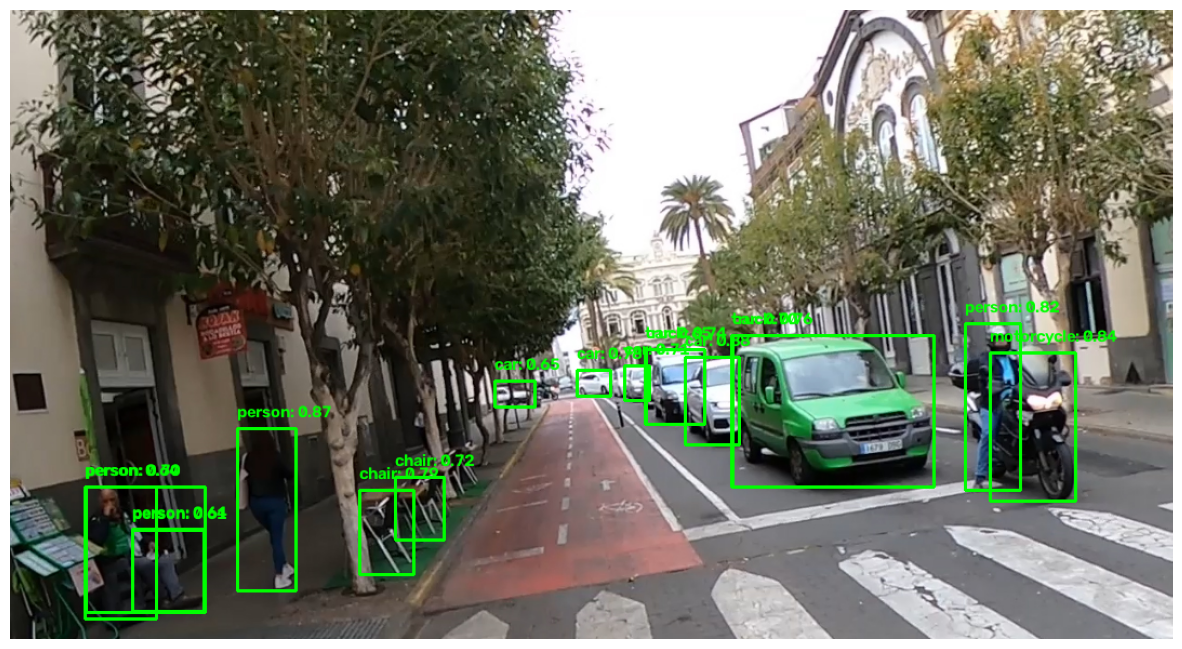

In [3]:
# Ejemplo de uso con imagen estática.

path_test = 'test.jpg'
image = cv2.imread(path_test)

boxes, scores, labels = detect(image, conf=0.6)

for box, score, label in zip(boxes, scores, labels):
    x1, y1, x2, y2 = box.astype(int)
    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(image, f"{CLASS_NAMES[label]}: {score:.2f}", (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
    
plt.figure(figsize=(15, 10))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis('off')



In [4]:
# Ejemplo de uso parecido al de YOLO. Detectar entrada desde la webcam.

vid = cv2.VideoCapture('C0142.MP4')
#vid = cv2.VideoCapture(0)
while True:
    ret, img = vid.read()

    if ret:
        boxes, scores, labels = detect(img, conf=0.4)

        for (x1, y1, x2, y2), score, cls in zip(boxes, scores, labels):
            color = tuple(int(c) for c in np.random.RandomState(int(cls)).randint(50, 255, 3))  # BGR
            cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), color, 3)
            cv2.putText(img, f"{CLASS_NAMES[int(cls)]} {score:.2f}", (int(x1), max(int(y1) - 8, 20)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)

        cv2.imshow("Vid", img)
        if cv2.waitKey(20) == 27:
            break

vid.release()
cv2.destroyAllWindows()

# Fase 1. Datos: UC3M-LP

Lectura del dataset, reescalado a 1280 px (lado mayor), conversión a COCO con una sola clase (matrícula), división train/val por bloques y visualización.

In [ ]:
import json, random
from pathlib import Path

DATASET_DIR = Path("DIRECTORIO")
DATA_DIR    = Path("data")                 # P4\data
IMG_OUT, ANN_OUT = DATA_DIR / "images", DATA_DIR / "annotations"
MAX_SIDE = 1280
SEED, VAL_FRAC, BLOQUE = 42, 0.15, 10
CATEGORIES = [{"id": 0, "name": "matricula"}]   # id 0: RT-DETR usa category_id como etiqueta (num_classes=1)

## 1. Lectura de UC3M-LP

Cada JSON se empareja con su imagen **por nombre de fichero**, porque el campo `imagePath` está desplazado. La caja de entrenamiento es la envolvente del polígono de 4 puntos.

In [5]:
def leer_split(split):
    """Empareja cada JSON con su imagen por nombre (imagePath no es fiable)."""
    img_dir, lbl_dir = DATASET_DIR / split / "images", DATASET_DIR / split / "labels"
    registros, sin_imagen = [], []
    for jf in sorted(lbl_dir.glob("*.json")):
        img_path = img_dir / f"{jf.stem}.jpg"
        if not img_path.exists():
            sin_imagen.append(jf.name); continue
        d = json.loads(jf.read_text(encoding="utf-8"))
        W, H = d["imageWidth"], d["imageHeight"]
        lps = []
        for lp in d["lps"]:
            poly = np.array(lp["poly_coord"], dtype=np.float32)
            poly[:, 0] = poly[:, 0].clip(0, W - 1); poly[:, 1] = poly[:, 1].clip(0, H - 1)
            (x1, y1), (x2, y2) = poly.min(0), poly.max(0)        # envolvente del polígono
            lps.append({"poly": poly, "bbox": [x1, y1, x2, y2], "text": lp["lp_id"],
                        "chars": [{"char": c["char_id"], "bbox": c["bbox_coord"]}
                                  for c in lp.get("characters", [])]})
        registros.append({"stem": jf.stem, "img_path": img_path, "width": W, "height": H, "lps": lps})
    return registros, sin_imagen

datos = {}
for s in ("train", "test"):
    datos[s], faltan = leer_split(s)
    print(f"{s}: {len(datos[s])} imágenes, {sum(len(r['lps']) for r in datos[s])} matrículas, sin imagen: {len(faltan)}")

train: 1580 imágenes, 2056 matrículas, sin imagen: 0
test: 395 imágenes, 491 matrículas, sin imagen: 0


## 2. Reescalado y conversión a COCO

Lado mayor a 1280 px y una sola clase. Se conservan el polígono, el texto (`lp_id` tal cual, la limpieza se hace en el OCR) y las cajas de los caracteres. Las imágenes ya reescaladas no se vuelven a generar.

In [7]:
def a_coco(registros, carpeta):
    """Reescala (lado mayor = MAX_SIDE) y genera el dict COCO conservando polígono, texto y caracteres."""
    (IMG_OUT / carpeta).mkdir(parents=True, exist_ok=True)
    images, anns = [], []
    for i, r in enumerate(registros):
        s = MAX_SIDE / max(r["width"], r["height"])
        w, h = round(r["width"] * s), round(r["height"] * s)
        dst = IMG_OUT / carpeta / f"{r['stem']}.jpg"
        if not dst.exists():                                     # no repite trabajo si ya existe
            img = cv2.resize(cv2.imread(str(r["img_path"])), (w, h), interpolation=cv2.INTER_AREA)
            cv2.imwrite(str(dst), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
        img_id = int(r["stem"])
        images.append({"id": img_id, "file_name": f"{carpeta}/{r['stem']}.jpg", "width": w, "height": h})
        for lp in r["lps"]:
            x1, y1, x2, y2 = (float(v * s) for v in lp["bbox"])
            poly = (lp["poly"] * s).round(2)
            anns.append({
                "id": len(anns) + 1, "image_id": img_id, "category_id": 0,
                "bbox": [x1, y1, x2 - x1, y2 - y1], "area": (x2 - x1) * (y2 - y1), "iscrowd": 0,
                "segmentation": [poly.flatten().tolist()], "poly": poly.tolist(),
                "text": lp["text"],                                   # tal cual; se limpia en el OCR
                "characters": [{"char": c["char"],
                                "bbox": [c["bbox"][0][0] * s, c["bbox"][0][1] * s,
                                         (c["bbox"][1][0] - c["bbox"][0][0]) * s,
                                         (c["bbox"][1][1] - c["bbox"][0][1]) * s]}
                               for c in lp["chars"]]})
        if (i + 1) % 200 == 0: print(f"  {carpeta}: {i + 1}/{len(registros)}")
    return {"images": images, "annotations": anns, "categories": CATEGORIES}

coco = {s: a_coco(datos[s], s) for s in ("train", "test")}

  train: 200/1580
  train: 400/1580
  train: 600/1580
  train: 800/1580
  train: 1000/1580
  train: 1200/1580
  train: 1400/1580
  test: 200/395


## 3. División train / val

El 15 % de train pasa a validación **por bloques de 10 fotos seguidas** (orden por nombre de fichero, semilla fija), para que un mismo coche no aparezca en ambos conjuntos. `test` no se toca hasta el final.

In [8]:
recs = sorted(datos["train"], key=lambda r: r["stem"])
bloques = [recs[i:i + BLOQUE] for i in range(0, len(recs), BLOQUE)]     # 10 fotos seguidas
idx = list(range(len(bloques))); random.Random(SEED).shuffle(idx)
val_ids = {int(r["stem"]) for i in idx[:round(VAL_FRAC * len(bloques))] for r in bloques[i]}

def filtrar(c, keep):
    return {"images": [im for im in c["images"] if keep(im["id"])],
            "annotations": [a for a in c["annotations"] if keep(a["image_id"])],
            "categories": c["categories"]}

splits = {"train": filtrar(coco["train"], lambda i: i not in val_ids),
          "val":   filtrar(coco["train"], lambda i: i in val_ids),
          "test":  coco["test"]}
ANN_OUT.mkdir(parents=True, exist_ok=True)
for name, c in splits.items():
    (ANN_OUT / f"{name}.json").write_text(json.dumps(c), encoding="utf-8")
    print(f"{name}: {len(c['images'])} imágenes, {len(c['annotations'])} matrículas")
assert not ({im["id"] for im in splits["train"]["images"]} & val_ids)

train: 1340 imágenes, 1771 matrículas
val: 240 imágenes, 285 matrículas
test: 395 imágenes, 491 matrículas


## 4. Visualización

Caja envolvente (verde), polígono (rojo) y texto de la matrícula sobre imágenes de train.

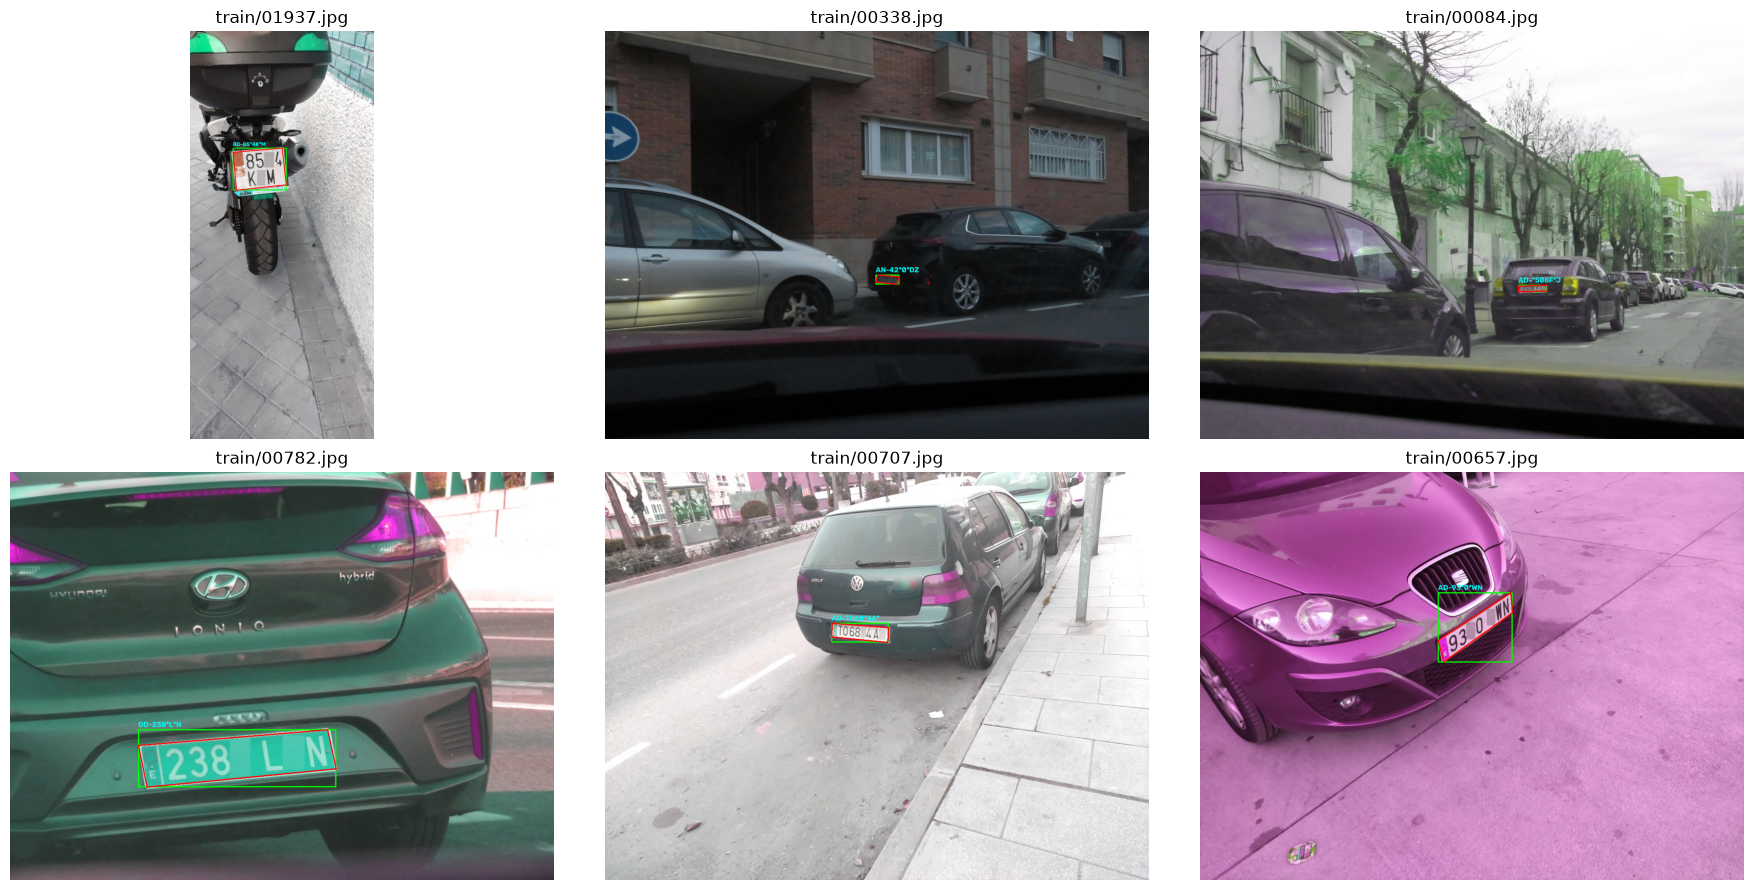

In [9]:
def dibujar(c, n=6, seed=SEED):
    anns_por_img = {}
    for a in c["annotations"]: anns_por_img.setdefault(a["image_id"], []).append(a)
    muestra = random.Random(seed).sample(c["images"], n)
    fig, axs = plt.subplots(2, (n + 1) // 2, figsize=(18, 9))
    for ax, im in zip(axs.ravel(), muestra):
        img = cv2.imread(str(IMG_OUT / im["file_name"]))
        for a in anns_por_img.get(im["id"], []):
            x, y, w, h = map(int, a["bbox"])
            cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)                       # caja
            cv2.polylines(img, [np.array(a["poly"], np.int32)], True, (0, 0, 255), 2)         # polígono
            cv2.putText(img, a["text"], (x, max(y - 6, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2)
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(im["file_name"]); ax.axis("off")
    plt.tight_layout(); plt.show()

dibujar(splits["train"])